In [605]:
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import pandas as pd
import requests

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [606]:
import warnings
warnings.filterwarnings('ignore')

In [607]:
pd.set_option('display.max_columns', 50)

In [608]:
df = pd.read_csv('it_vacancies.csv')

In [609]:
df.head(10)

,id,area,name,vacancy_url,published_at,created_at,archived,premium,salary_from,salary_to,salary_gross,currency,salary_frequency,profession_roles,profession_role_ids,experience,experience_id,employment_form,employment_form_id,work_format,working_hours,work_schedule_by_days,internship,has_test,response_letter_required,key_skills,employer,employer_name,employer_trusted,employer_accredited_it_employer,description
0,135316270,Москва,Старший специалист технической поддержки,https://hh.ru/vacancy/135316270,2026-08-29T10:56:55+0300,2026-08-29T10:56:55+0300,False,False,NaN,NaN,NaN,NaN,NaN,Специалист технической поддержки,121,От 3 до 6 лет,between3And6,Полная,FULL,На месте работодателя,8 часов,5/2,False,False,False,NaN,9990687.0,Интернет-энциклопедия РУВИКИ,True,False,Рувики- новая интернет-энциклопедия.Наш продук...
1,136627916,Москва,Специалист технической поддержки,https://hh.ru/vacancy/136627916,2026-08-29T10:41:26+0300,2026-08-29T10:41:26+0300,False,False,NaN,NaN,NaN,NaN,NaN,Специалист технической поддержки,121,От 1 года до 3 лет,between1And3,Полная,FULL,На месте работодателя,8 часов,5/2,False,False,False,Техническая поддержка | Настройка ПО | Работа ...,2761777.0,Эртивиай Продакшн,True,False,Обязанности:2-я линия технической поддержки ра...
2,136438776,Москва,Руководитель проектов (дизайн интерьеров общес...,https://hh.ru/vacancy/136438776,2026-08-29T10:41:01+0300,2026-08-29T10:41:01+0300,False,False,NaN,200000.0,False,RUR,NaN,Руководитель проектов,107,Более 6 лет,moreThan6,Полная,FULL,Удалённо | Гибрид,8 часов,5/2,False,False,True,Project management | Английский язык | Управле...,2337196.0,Дизайн-студия Sundukovy Sisters,True,False,Студия S+Sзанимается дизайном интерьеров общес...
3,136297205,Москва,Специалист службы поддержки (чаты),https://hh.ru/vacancy/136297205,2026-08-29T10:40:51+0300,2026-08-29T10:40:51+0300,False,False,80000.0,120000.0,True,RUR,Два раза в месяц,Специалист технической поддержки,121,От 1 года до 3 лет,between1And3,Полная,FULL,Удалённо,8 часов,5/2,False,False,False,Деловая переписка | wildberries | Ozon | Марке...,10058188.0,ТехноСтиль,True,False,Прайс Ниндзя - это платформа управления ценами...
4,136296407,Москва,"Системный аналитик Junior (SQL, SOAP, REST) В ...",https://hh.ru/vacancy/136296407,2026-08-29T10:32:45+0300,2026-08-29T10:32:45+0300,False,False,70000.0,90000.0,True,RUR,Два раза в месяц,Системный аналитик,148,Нет опыта,noExperience,Полная,FULL,На месте работодателя | Гибрид,8 часов,5/2,False,False,False,Системный анализ | Постановка задач разработчи...,3197321.0,Кузница Кадров,True,False,Внимание! Трудоустройство напрямую к работодат...
5,136296220,Москва,Senior Python Developer,https://hh.ru/vacancy/136296220,2026-08-29T10:30:06+0300,2026-08-29T10:30:06+0300,False,False,NaN,NaN,NaN,NaN,NaN,"Программист, разработчик",96,Более 6 лет,moreThan6,Полная,FULL,Удалённо,8 часов,5/2,False,False,True,Python | SQLAlchemy | asyncio | GraphQL | Post...,5032843.0,Филиал компании Лист Ренталс Лимитед,True,False,Обязанности:Поддержка уже существующих проекто...
6,135176066,Москва,C#/.NET-разработчик (Middle+/Senior),https://hh.ru/vacancy/135176066,2026-08-29T10:29:54+0300,2026-08-29T10:29:54+0300,False,False,3500.0,4500.0,False,USD,Раз в месяц,"Программист, разработчик",96,От 3 до 6 лет,between3And6,Полная,FULL,Удалённо,8 часов,5/2,False,False,False,PostgreSQL | SQL | С# | Проектирование высокон...,2242391.0,IndigoSoft,True,False,Indigosoft— международный Fintech-провайдер с ...
7,50584337,Москва,Консультант 1С по бюджетному учету,https://hh.ru/vacancy/50584337,2026-08-29T10:28:29+0300,2026-08-29T10:28:29+0300,False,False,90000.0,NaN,True,RUR,NaN,"Программист, разработчик",96,От 3 до 6 лет,between3And6,Полная,FULL,NaN,8 часов,5/2,False,False,False,1С: Зарплата и кадры | 1С: Бухгалтерия | Бухга...,2682308.0,Центр инновационных услуг,True,False,Обязанности:Консультирование клиентов по вопро...
8,136437658,Москва,Руководитель проектов (промышленная автоматиза...,https://hh.ru/vacancy/136437658,2026-08-29T10:27:24+03

In [610]:
df.shape

(15027, 31)

In [611]:
df.columns

Index(['id', 'area', 'name', 'vacancy_url', 'published_at', 'created_at',
       'archived', 'premium', 'salary_from', 'salary_to', 'salary_gross',
       'currency', 'salary_frequency', 'profession_roles',
       'profession_role_ids', 'experience', 'experience_id', 'employment_form',
       'employment_form_id', 'work_format', 'working_hours',
       'work_schedule_by_days', 'internship', 'has_test',
       'response_letter_required', 'key_skills', 'employer', 'employer_name',
       'employer_trusted', 'employer_accredited_it_employer', 'description'],
      dtype='object')

In [612]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15027 entries, 0 to 15026
Data columns (total 31 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   id                               15027 non-null  int64  
 1   area                             15027 non-null  object 
 2   name                             15027 non-null  object 
 3   vacancy_url                      15027 non-null  object 
 4   published_at                     15027 non-null  object 
 5   created_at                       15027 non-null  object 
 6   archived                         15027 non-null  bool   
 7   premium                          15027 non-null  bool   
 8   salary_from                      3510 non-null   float64
 9   salary_to                        2559 non-null   float64
 10  salary_gross                     4196 non-null   object 
 11  currency                         4196 non-null   object 
 12  salary_frequency  

In [613]:
SKILL_ALIASES = {
    'Apache Kafka': 'Kafka',
    'Golang': 'Go',
    'HTML5': 'HTML',
    'Администрирование серверов Linux': 'Администрирование серверов',
    'Администрирование серверов Windows': 'Администрирование серверов',
    # bad_skill: good_skill
}

def normalize_skills(value):
    if pd.isna(value):
        return None
    
    skills = value.split(' | ')
    
    skills = [SKILL_ALIASES.get(skill, skill) for skill in skills]
    
    skills = set(skills)
    return ' | '.join(skills)


df['key_skills'] = df['key_skills'].apply(normalize_skills)

In [614]:
missing = (
    df.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print('Доля пропусков:')
print(missing.round(1))

Доля пропусков:
salary_to                          83.0
salary_frequency                   81.4
salary_from                        76.6
currency                           72.1
salary_gross                       72.1
key_skills                         43.3
work_format                         1.0
employer                            0.6
employer_accredited_it_employer     0.6
work_schedule_by_days               0.1
employer_trusted                    0.1
working_hours                       0.0
response_letter_required            0.0
employment_form_id                  0.0
employer_name                       0.0
has_test                            0.0
internship                          0.0
id                                  0.0
experience                          0.0
employment_form                     0.0
experience_id                       0.0
area                                0.0
profession_role_ids                 0.0
profession_roles                    0.0
premium                 

In [615]:
df['published_at'] = pd.to_datetime(df['published_at'])

df['created_at'] = pd.to_datetime(df['created_at'])

In [616]:
df['currency'].value_counts()

currency
RUR    4107
USD      75
EUR      13
BYR       1
Name: count, dtype: int64

In [617]:
def get_currency_rates():
    url = 'https://www.cbr.ru/currency_base/daily/'
    response = requests.get(url)
    usd = 83
    eur = 93
    byn = 27
    if response.status_code == 200:
        soup = BeautifulSoup(response.text, 'html.parser')
        rows = soup.find('table', class_='data').find_all('tr')
        for row in rows[1:]:
            columns = row.find_all('td')
            if columns[1].text == 'USD':
                usd = columns[4].text
                usd = float(usd.replace(',', '.'))
            elif columns[1].text == 'EUR':
                eur = columns[4].text
                eur = float(eur.replace(',', '.'))
            elif columns[1].text == 'BYN':
                byn = columns[4].text
                byn = float(byn.replace(',', '.'))
        return usd, eur, byn

In [618]:
usd, eur, byn = get_currency_rates()

In [619]:
df.loc[df['currency'] == 'USD', 'rate'] = usd
df.loc[df['currency'] == 'EUR', 'rate'] = eur
df.loc[df['currency'] == 'BYR', 'rate'] = byn
df.loc[df['currency'] == 'RUR', 'rate'] = 1

In [620]:
salary_df = df.copy()

In [621]:
# убираем агентские перепостинги
salary_df = salary_df.drop_duplicates(subset=['name', 'salary_from', 'salary_to', 'key_skills', 'description'])

In [622]:
print('Периодичность зарплаты:')
salary_df['salary_frequency'].value_counts()

Периодичность зарплаты:


salary_frequency
Два раза в месяц    2419
Раз в месяц          273
Раз в неделю          42
За проект             33
Ежедневно              8
Name: count, dtype: int64

In [623]:
# переводим все зарплаты в рубли
salary_df['salary_from'] = salary_df['salary_from'] * salary_df['rate']
salary_df['salary_to'] = salary_df['salary_to'] * salary_df['rate']

In [624]:
salary_df['salary'] = (
    salary_df[['salary_from', 'salary_to']].mean(axis=1)
)
#Среднее арифметическое по каждой зарплатной вилке.

In [625]:
salary_df['salary_type'] = 'range'

salary_df.loc[salary_df['salary_from'].isna(), 'salary_type'] = 'only_to'
salary_df.loc[salary_df['salary_to'].isna(), 'salary_type'] = 'only_from'
salary_df.loc[salary_df[['salary_from', 'salary_to']].isna().all(axis=1), 'salary_type'] = 'missing'
#Добавляем категории "Только от" "Только До" "От и До" и "Не указано".

In [626]:
salary_df = salary_df.dropna(subset=['salary'])

print('Вакансий всего:')
print(len(df))

print('Доля вакансий, пригодных для анализа зарплат:')
print(round(len(salary_df) / len(df) * 100, 2), '%')

Вакансий всего:
15027
Доля вакансий, пригодных для анализа зарплат:
27.65 %


In [627]:
print('Статистика зарплат:')

salary_df['salary'].describe().round()

Статистика зарплат:


count      4155.0
mean     173973.0
std       96788.0
min         105.0
25%      108150.0
50%      150000.0
75%      217500.0
max      900000.0
Name: salary, dtype: float64

In [628]:
salary_by_exp = (
    salary_df
    .groupby('experience')
    .agg(
        vacancies=('id', 'count'),
        median_salary=('salary', 'median'),
        mean_salary=('salary', 'mean')
    )
    .sort_values(
        'median_salary',
        ascending=False
    )
)

print('Зарплата по опыту:')
salary_by_exp.round(1)

Зарплата по опыту:


,vacancies,median_salary,mean_salary
experience,,,
Более 6 лет,301,275000.0,301158.9
От 3 до 6 лет,1505,200000.0,212702.4
От 1 года до 3 лет,2018,125000.0,137973.6
Нет опыта,331,80000.0,101693.0


In [629]:
salary_by_role = (
    salary_df
    .groupby('profession_roles')
    .agg(
        vacancies=('id', 'count'),
        median_salary=('salary', 'median'),
        mean_salary=('salary', 'mean')
    )
    .sort_values(
        'median_salary',
        ascending=False
    )
)

In [630]:
salary_by_role = (
    salary_by_role[
        salary_by_role['vacancies'] >= 10
    ]
    .sort_values(
        'median_salary',
        ascending=False
    )
)

print('Зарплата по профессиям:')
salary_by_role.head(20).round(1)

Зарплата по профессиям:


,vacancies,median_salary,mean_salary
profession_roles,,,
Руководитель группы разработки,66,325000.0,335290.2
Дата-сайентист,49,250000.0,257570.2
Директор по информационным технологиям (CIO),22,250000.0,303401.8
DevOps-инженер,81,250000.0,245564.3
Руководитель отдела аналитики,23,250000.0,285187.0
Системный аналитик,96,227500.0,238666.7
"Программист, разработчик",579,200000.0,223647.9
"Арт-директор, креативный директор",28,195000.0,184821.4
Бизнес-аналитик,102,185000.0,192076.1


In [631]:
salary_by_format = (
     salary_df
     .groupby('work_format')
     .agg(
         vacancies=('id', 'count'),
         median_salary=('salary', 'median'),
         mean_salary=('salary', 'mean')
     )
     .sort_values(
         'vacancies',
         ascending=False
     )
 )

print('Зарплата по формату работы:')
salary_by_format.round(1)

Зарплата по формату работы:


,vacancies,median_salary,mean_salary
work_format,,,
На месте работодателя,2258,150000.0,166247.5
Удалённо,853,150000.0,173578.1
На месте работодателя | Гибрид,254,177500.0,192244.9
Гибрид,246,175000.0,197887.4
На месте работодателя | Удалённо | Гибрид,115,185000.0,217517.6
На месте работодателя | Разъездной,111,150000.0,173432.8
Удалённо | Гибрид,96,200000.0,208114.6
Разъездной,83,125000.0,141969.6
На месте работодателя | Удалённо,38,196250.0,199868.2


In [632]:
salary_by_accred = (
    salary_df
    .groupby('employer_accredited_it_employer')
    .agg(
        vacancies=('id', 'count'),
        median_salary=('salary', 'median'),
        mean_salary=('salary', 'mean')
    )
    .sort_values(
        'median_salary',
        ascending=False
    )
)

print('Зарплата в разрезе аккредитации компании:')
salary_by_accred.round(1)

Зарплата в разрезе аккредитации компании:


,vacancies,median_salary,mean_salary
employer_accredited_it_employer,,,
True,520,174500.0,180773.0
False,3614,150000.0,172651.1


In [633]:
skills = (
    salary_df['key_skills']
    .dropna()
    .str.split(' | ', regex=False)
    .explode()
    .str.strip()
)

In [634]:
top_skills = (
    skills
    .value_counts()
    .head(50)
)

print('Самые частые требуемые навыки:')
top_skills

Самые частые требуемые навыки:


key_skills
Деловая коммуникация                       267
Аналитическое мышление                     233
SQL                                        232
Linux                                      231
Работа с большим объемом информации        221
Организаторские навыки                     203
Деловая переписка                          185
Adobe Photoshop                            182
Деловое общение                            181
Техническая поддержка                      171
Python                                     159
Настройка ПК                               159
Администрирование серверов                 151
Настройка сетевых подключений              149
PostgreSQL                                 148
Git                                        140
Настройка ПО                               128
Администрирование сетевого оборудования    123
Docker                                     119
Управление командой                        118
Английский язык                            115
Ad

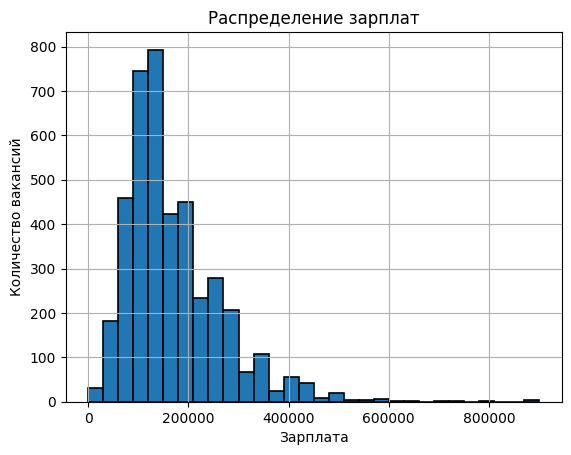

In [635]:
salary_df['salary'].plot(kind='hist', bins=30, edgecolor='k', linewidth=1.2)
# k - black

plt.title('Распределение зарплат')
plt.xlabel('Зарплата')
plt.ylabel('Количество вакансий')
plt.grid(True);

In [636]:
exp_order = ['Нет опыта', 'От 1 года до 3 лет', 'От 3 до 6 лет', 'Более 6 лет']

In [637]:
plot_data = [
    salary_df.loc[
        salary_df['experience'].eq(experience),
    'salary',
    ].dropna()
    for experience in exp_order
]

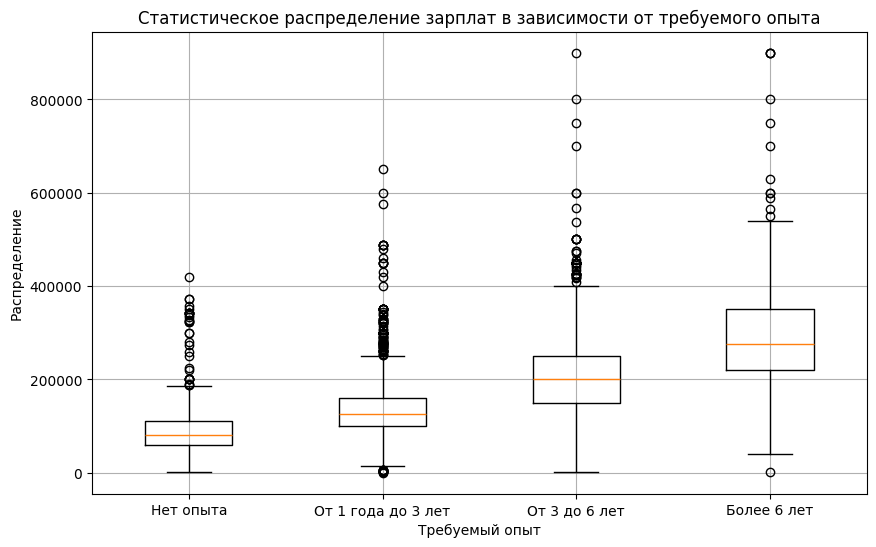

In [638]:
plt.figure(figsize=(10, 6))
plt.boxplot(
    plot_data,
    labels=exp_order
);

plt.title('Статистическое распределение зарплат в зависимости от требуемого опыта')
plt.xlabel('Требуемый опыт')
plt.ylabel('Распределение')
plt.grid(True);

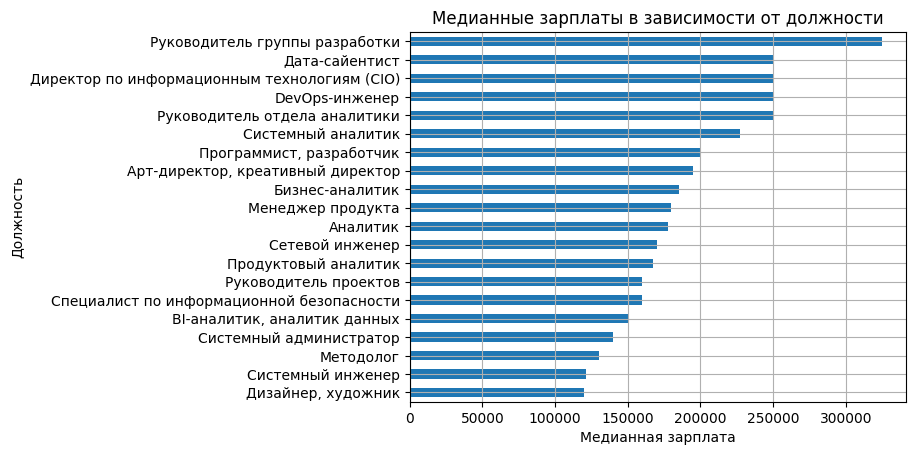

In [639]:
(
    salary_by_role
    .head(20)
    .sort_values('median_salary')
    ['median_salary']
    .plot(kind='barh')
);

plt.title('Медианные зарплаты в зависимости от должности')
plt.xlabel('Медианная зарплата')
plt.ylabel('Должность')
plt.grid(True);

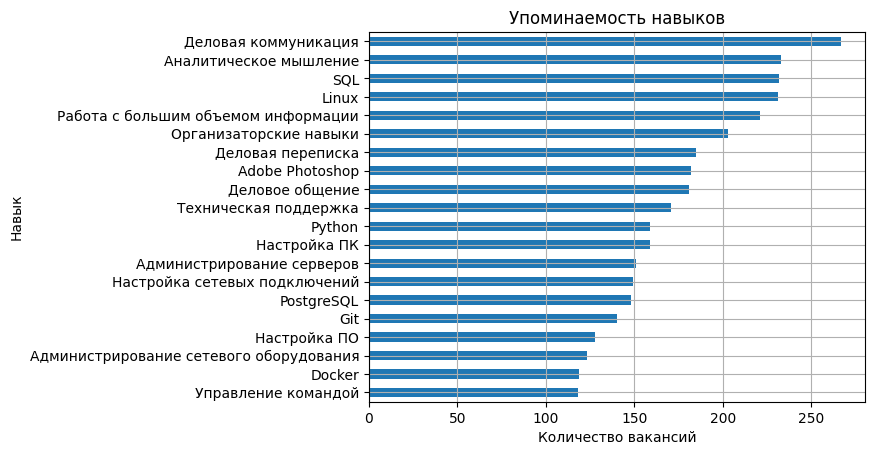

In [640]:
(
    top_skills
    .head(20)
    .sort_values()
    .plot(kind='barh')
);

plt.title('Упоминаемость навыков')
plt.xlabel('Количество вакансий')
plt.ylabel('Навык')
plt.grid(True);

In [641]:
skills_salary = (
    salary_df[['id', 'salary', 'key_skills']]
    .dropna(subset=['key_skills'])
    .assign(
        skill=lambda x: x['key_skills'].str.split(' | ', regex=False)
    )
    .explode('skill')
)

skills_salary = (
    skills_salary
    .groupby('skill')
    .agg(
        vacancies=('id', 'nunique'),
        median_salary=('salary', 'median')
    )
)

skills_salary = (
    skills_salary[skills_salary['vacancies'] >= 10]
    .sort_values('median_salary', ascending=False)
)

print('Влияние навыков на медианную зарплату:')
skills_salary.head(30)

Влияние навыков на медианную зарплату:


,vacancies,median_salary
skill,,
Проведение переговоров,12,342500.000
Договорная работа,10,342500.000
Теплые продажи,15,342500.000
Микросервисная архитектура,11,330000.000
С#,11,300000.000
Go,30,300000.000
Внутренние коммуникации,12,296250.000
Spring Framework,11,290000.000
ML,10,278101.775


## Подготовка данных для кластеризации

In [642]:
EXP_MAP = {
    'noExperience': 0,
    'between1And3': 1,
    'between3And6': 2,
    'moreThan6': 3,
}

In [643]:
salary_df['experience_num'] = salary_df['experience_id'].map(EXP_MAP)

In [644]:
# считаем, сколько скиллов требуется по каждой из вакансий
salary_df['skills_count'] = df['key_skills'].fillna('').apply(
    lambda value: 0 if value == '' else len(value.split(' | '))
)

In [645]:
# переводим True/False -> 1/0
salary_df['internship_num'] = salary_df['internship'].fillna(False).astype(int)
salary_df['has_test_num'] = salary_df['has_test'].fillna(False).astype(int)
salary_df['employer_accredited_it_employer_num'] = salary_df['employer_accredited_it_employer'].fillna(False).astype(int)

In [646]:
# переводим в 1/0 уникальные значени в выбранных колонках 
# (Удаленно / На месте -> 1 / 1 / 0 / 0)
def make_dummies(column, prefix):
    return (salary_df[column]
            .fillna('')
            .str.replace(r'\s*\|\s*', '|', regex=True)
            .str.get_dummies(sep='|')
            .add_prefix(prefix)
           )


In [647]:
work_format_dummies = make_dummies('work_format', 'format_')
employment_dummies = make_dummies('employment_form', 'employment_')
working_hours_dummies = make_dummies('working_hours', 'hours_')
schedule_dummies = make_dummies('work_schedule_by_days', 'schedule_')

In [648]:
skills_dummies = salary_df['key_skills'].fillna('').str.get_dummies(sep=' | ')

skills_freq = (
    skills_dummies
    .sum()
    .sort_values(ascending=False)
)

TOP_SKILLS = (
    skills_freq
    .head(30)
    .index
)

skills_dummies = (
    skills_dummies[TOP_SKILLS]
    .add_prefix('skill_')
)

In [649]:
TOP_SKILLS

Index(['SQL', 'Linux', 'Python', 'PostgreSQL', 'Git', 'Docker',
       'Бизнес-анализ', 'Дизайн', 'Figma', '1С', 'TCP/IP', 'Kafka',
       'Kubernetes', 'BPMN', 'Zabbix', 'Ответственность', 'Helpdesk', 'API',
       'JavaScript', 'Java', 'CI/CD', 'HTML', 'UML', 'Администрирование',
       'MySQL', 'CorelDRAW', 'PHP', 'Agile', 'Клиентоориентированность',
       'RabbitMQ'],
      dtype='object')

In [650]:
base_df = salary_df[
    [
        'experience_num',
        'skills_count',
        'internship_num',
        'has_test_num',
        'employer_accredited_it_employer_num',
        
    ]
].copy()

In [651]:
# сборка всех числовых параметров для дальнейшей кластеризации в единый датафрейм
X_cluster = pd.concat(
    [
        base_df,
        skills_dummies,
        work_format_dummies,
        employment_dummies,
        working_hours_dummies,
        schedule_dummies,
    ],
    axis=1
)

## Признаки для кластеризации

In [652]:
X_cluster.columns

Index(['experience_num', 'skills_count', 'internship_num', 'has_test_num',
       'employer_accredited_it_employer_num', 'skill_SQL', 'skill_Linux',
       'skill_Python', 'skill_PostgreSQL', 'skill_Git', 'skill_Docker',
       'skill_Бизнес-анализ', 'skill_Дизайн', 'skill_Figma', 'skill_1С',
       'skill_TCP/IP', 'skill_Kafka', 'skill_Kubernetes', 'skill_BPMN',
       'skill_Zabbix', 'skill_Ответственность', 'skill_Helpdesk', 'skill_API',
       'skill_JavaScript', 'skill_Java', 'skill_CI/CD', 'skill_HTML',
       'skill_UML', 'skill_Администрирование', 'skill_MySQL',
       'skill_CorelDRAW', 'skill_PHP', 'skill_Agile',
       'skill_Клиентоориентированность', 'skill_RabbitMQ', 'format_Гибрид',
       'format_На месте работодателя', 'format_Разъездной', 'format_Удалённо',
       'employment_Вахта', 'employment_Подработка', 'employment_Полная',
       'employment_Проект', 'employment_Частичная', 'hours_10 часов',
       'hours_11 часов', 'hours_12 часов', 'hours_24 часа', 'hours_2 ча

In [653]:
X_cluster

,experience_num,skills_count,internship_num,has_test_num,employer_accredited_it_employer_num,skill_SQL,skill_Linux,skill_Python,skill_PostgreSQL,skill_Git,skill_Docker,skill_Бизнес-анализ,skill_Дизайн,skill_Figma,skill_1С,skill_TCP/IP,skill_Kafka,skill_Kubernetes,skill_BPMN,skill_Zabbix,skill_Ответственность,skill_Helpdesk,skill_API,skill_JavaScript,skill_Java,...,hours_24 часа,hours_2 часа,hours_3 часа,hours_4 часа,hours_5 часов,hours_6 часов,hours_7 часов,hours_8 часов,hours_9 часов,hours_Другое,hours_По договорённости,schedule_1/2,schedule_1/3,schedule_2/1,schedule_2/2,schedule_3/2,schedule_3/3,schedule_4/2,schedule_4/3,schedule_4/4,schedule_5/2,schedule_6/1,schedule_Другое,schedule_По выходным,schedule_Свободный
2,3,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
3,1,10,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
4,0,9,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
6,2,10,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
7,2,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14998,2,6,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
15012,1,5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
15014,1,6,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
15020,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0


Проводим скалирование значений

In [654]:
scaler = StandardScaler()

In [655]:
X_scaled = scaler.fit_transform(X_cluster)

Подбираем количество кластеров по silhouette_score

In [656]:
scores = {}

for k in range(4, 7):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    
    labels = model.fit_predict(X_scaled)
    
    score = silhouette_score(X_scaled, labels, random_state=42)
    
    scores[k] = score

In [657]:
best_k = max(scores, key=scores.get)

print(f'Выбрано кластеров: {best_k}')

Выбрано кластеров: 6


Проводим кластеризацию

In [658]:
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)

salary_df['cluster'] = kmeans.fit_predict(X_scaled)

In [659]:
cluster_sizes = salary_df['cluster'].value_counts().sort_index()

cluster_sizes

cluster
0     256
1    3599
2      46
3     232
4      15
5       7
Name: count, dtype: int64

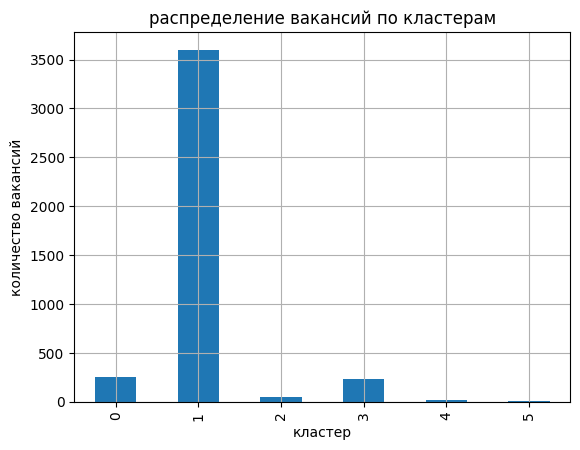

In [660]:
cluster_sizes.plot(kind='bar');

plt.title('Распределение вакансий по кластерам')
plt.xlabel('Кластер')
plt.ylabel('Количество вакансий')
plt.grid(True);

In [661]:
salary_by_cluster = (
    salary_df
    .groupby('cluster')
    .agg(
        vacancies=(
            'id',
            'count',
        ),
        median_salary=(
            'salary',
            'median',
        ),
        median_exp=(
            'experience_num',
            'median',
        ),
        median_skills_count=(
            'skills_count',
            'median',
        ),
    )
)

print('Уровень зарплаты и среднее количество требуемых навыков в зависимости от кластера')
salary_by_cluster

Уровень зарплаты и среднее количество требуемых навыков в зависимости от кластера


,vacancies,median_salary,median_exp,median_skills_count
cluster,,,,
0,256,90000.0,1.0,4.0
1,3599,150000.0,1.0,4.0
2,46,200000.0,2.0,8.0
3,232,210000.0,2.0,10.0
4,15,100000.0,1.0,6.0
5,7,120000.0,0.0,7.0


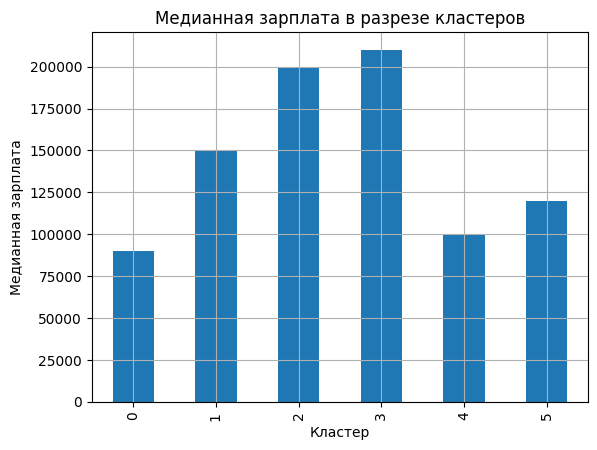

In [662]:
salary_by_cluster['median_salary'].plot(kind='bar')

plt.title('Медианная зарплата в разрезе кластеров')
plt.xlabel('Кластер')
plt.ylabel('Медианная зарплата')
plt.grid(True);

## Какие навыки характерны для каждого кластера

In [663]:
cluster_skills = (
    salary_df[['cluster', 'key_skills']]
    .dropna(subset=['key_skills'])
    .assign(skill=lambda data: data['key_skills'].str.split(' | ', regex=False))
    .explode('skill')
)

In [664]:
cluster_skills

,cluster,key_skills,skill
2,1,Organization Skills | Английский язык | Projec...,Organization Skills
2,1,Organization Skills | Английский язык | Projec...,Английский язык
2,1,Organization Skills | Английский язык | Projec...,Project management
2,1,Organization Skills | Английский язык | Projec...,Управление коммуникациями
3,1,Работа с клиентами | wildberries | Техническая...,Работа с клиентами
...,...,...,...
15014,1,Оптимизация бизнес-процессов | Анализ данных |...,Анализ данных
15014,1,Оптимизация бизнес-процессов | Анализ данных |...,Информационные технологии
15014,1,Оптимизация бизнес-процессов | Анализ данных |...,Аналитические исследования
15014,1,Оптимизация бизнес-процессов | Анализ данных |...,Аналитика


In [665]:
top_skills_by_cluster = (
    cluster_skills
    .groupby(['cluster', 'skill'])
    .size()
    .rename('vacancies')
    .reset_index()
    .sort_values(['cluster', 'vacancies'], ascending=[True, False])
    .groupby('cluster')
    .head(5)
    
)

In [670]:
print('Топ-5 навыков, требуемых в каждом из кластеров')
top_skills_by_cluster.reset_index(drop=True)

Топ-5 навыков, требуемых в каждом из кластеров


,cluster,skill,vacancies
0,0,Деловое общение,34
1,0,Навыки продаж,33
2,0,Техническая поддержка,28
3,0,Активные продажи,26
4,0,Деловая переписка,25
5,1,Деловая коммуникация,251
6,1,Аналитическое мышление,224
7,1,Работа с большим объемом информации,202
8,1,Организаторские навыки,187
9,1,Adobe Photoshop,160


## Какие профессии оказались в каждом кластере

In [667]:
cluster_roles = (
    salary_df[['cluster', 'profession_roles']]
    .dropna(subset=['profession_roles'])
    .assign(role=lambda data: data['profession_roles'].str.split(' | ', regex=False))
    .explode('role')
)

In [668]:
top_roles_by_cluster = (
    cluster_roles
    .groupby(['cluster', 'role'])
    .size()
    .rename('vacancies')
    .reset_index()
    .sort_values(['cluster', 'vacancies'], ascending=[True, False])
    .groupby('cluster')
    .head(5)
)

In [671]:
print('Топ-5 профессий в каждом из кластеров')
top_roles_by_cluster.reset_index(drop=True)

Топ-5 профессий в каждом из кластеров


,cluster,role,vacancies
0,0,"Дизайнер, художник",102
1,0,Специалист технической поддержки,102
2,0,Системный администратор,21
3,0,"Программист, разработчик",7
4,0,Руководитель проектов,5
5,1,Руководитель проектов,580
6,1,"Дизайнер, художник",480
7,1,"Программист, разработчик",454
8,1,Специалист технической поддержки,328
9,1,Системный администратор,323
